# Colorado River Basin: Data Pipeline & Sample Code

**Author:** Douglas Schoch • **Course:** DAT1001: Introduction to Data Science (Colorado Mountain College)  
**Live Dashboard:** [schochdo.github.io/colorado_river](https://schochdo.github.io/colorado_river/index.html) • **Repository:** [github.com/schochdo/CO_River](https://github.com/schochdo/CO_River)

Each of the **5 short code blocks** below is self-contained and runnable directly in **Jupyter, Google Colab, or Spyder** (if `data/colorado_river_basin.db` is not present locally, Blocks 3–5 automatically fetch the 2.9 MB SQLite database from GitHub).


## 1. Live USGS Streamflow API (`requests` → 7-Day Hydrograph)
Queries 15-minute discharge (`parameterCd=00060`, cubic feet per second) from the USGS Water Services REST API for **Lee's Ferry (`#09380000`)** and **Cisco (`#09180500`)**.


COLORADO RIVER NEAR CISCO, UT: 2,600 cfs (latest)
COLORADO RIVER AT LEES FERRY, AZ: 8,350 cfs (latest)


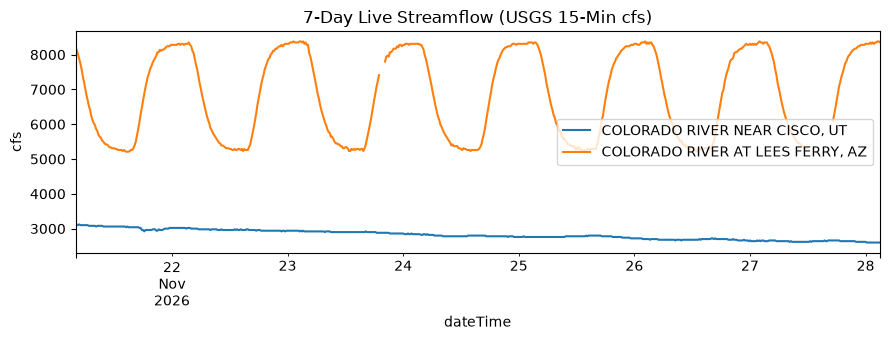

In [1]:
import requests, pandas as pd, matplotlib.pyplot as plt

resp = requests.get('https://waterservices.usgs.gov/nwis/iv/', params={
    'sites': '09380000,09180500', 'parameterCd': '00060', 'period': 'P7D', 'format': 'json'
}, timeout=15).json()

series = {}
for ts in resp['value']['timeSeries']:
    pts = pd.DataFrame(ts['values'][0]['value'])
    if pts.empty:
        continue
    name = ts['sourceInfo']['siteName']
    s = pd.Series(pd.to_numeric(pts['value'], errors='coerce').values, index=pd.to_datetime(pts['dateTime'], utc=True)).dropna()
    s = s[s >= 0]
    if not s.empty:
        series[name] = s
        print(f"{name}: {s.iloc[-1]:,.0f} cfs (latest)")

pd.DataFrame(series).plot(figsize=(9, 3.5), title='7-Day Live Streamflow (USGS 15-Min cfs)', ylabel='cfs')
plt.tight_layout(); plt.show()


## 2. Live USBR Reservoir CSVs (`pandas` → Powell & Mead Storage)
Downloads daily reservoir storage (`17.csv`, Acre-Feet) directly from the U.S. Bureau of Reclamation for **Lake Powell (`Site 919`)** and **Lake Mead (`Site 921`)** and converts to Million Acre-Feet (`MAF`).


Lake Powell: 6.53 MAF (as of 2026-11-26)


Lake Mead: 7.07 MAF (as of 2026-11-26)


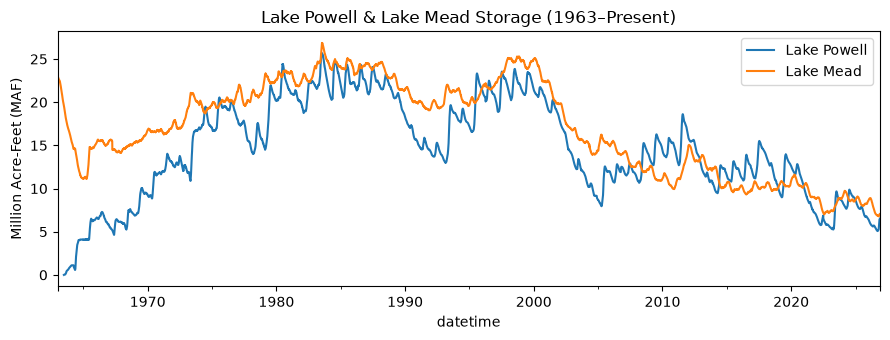

In [2]:
import pandas as pd, matplotlib.pyplot as plt

urls = {
    'Lake Powell': 'https://www.usbr.gov/uc/water/hydrodata/reservoir_data/919/csv/17.csv',
    'Lake Mead':   'https://www.usbr.gov/uc/water/hydrodata/reservoir_data/921/csv/17.csv',
}
frames = {}
for name, url in urls.items():
    df = pd.read_csv(url, parse_dates=['datetime']).dropna()
    frames[name] = df.set_index('datetime').iloc[:, 0] / 1_000_000
    print(f"{name}: {frames[name].iloc[-1]:.2f} MAF (as of {frames[name].index[-1].date()})")

pd.DataFrame(frames).loc['1963':].plot(figsize=(9, 3.5), title='Lake Powell & Lake Mead Storage (1963–Present)', ylabel='Million Acre-Feet (MAF)')
plt.tight_layout(); plt.show()


## 3. SQLite Database Connection & Compact Deficit (`1922–2024`)
Connects to `colorado_river_basin.db` and compares unimpaired **Lees Ferry Natural Flow** against the `16.50 MAF/yr` Compact + Mexican Treaty allocation (`15.0` domestic + `1.5` Mexico).


Years below 16.50 MAF target: 70 of 103 water years


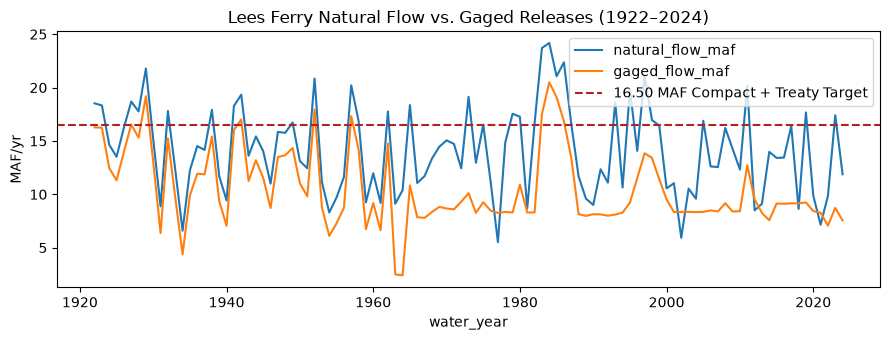

In [3]:
import sqlite3, tempfile, urllib.request, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path

db_path = next((p for p in [Path('data/colorado_river_basin.db'), Path('../data/colorado_river_basin.db')] if p.exists()), None)
if db_path is None:
    db_path = Path(tempfile.gettempdir()) / 'colorado_river_basin.db'
    if not db_path.exists():
        urllib.request.urlretrieve('https://raw.githubusercontent.com/schochdo/CO_River/main/data/colorado_river_basin.db', db_path)

conn = sqlite3.connect(db_path)
df_lf = pd.read_sql_query('SELECT water_year, natural_flow_maf, gaged_flow_maf FROM annual_lees_ferry WHERE water_year >= 1922 ORDER BY water_year', conn)
print(f"Years below 16.50 MAF target: {(df_lf['natural_flow_maf'] < 16.5).sum()} of {len(df_lf)} water years")

ax = df_lf.plot(x='water_year', y=['natural_flow_maf', 'gaged_flow_maf'], figsize=(9, 3.5), ylabel='MAF/yr', title='Lees Ferry Natural Flow vs. Gaged Releases (1922–2024)')
ax.axhline(16.5, ls='--', color='firebrick', label='16.50 MAF Compact + Treaty Target'); ax.legend()
plt.tight_layout(); plt.show()


## 4. SQL Join: Richards–Baker Flashiness Index (`RBI`) Across 74 Gages
Joins `rbi_flashiness` with `station_daily_normals` in SQLite, converts mean discharge (`cfs`) to annual volume (`1 cfs × 1 yr = 0.00072397 MAF`), and plots all 74 gages by flow regime.


             rbi_index  annual_maf
flow_regime                       
Flashy           0.284       0.087
Regulated        0.048       0.502
Snowmelt         0.082       0.668


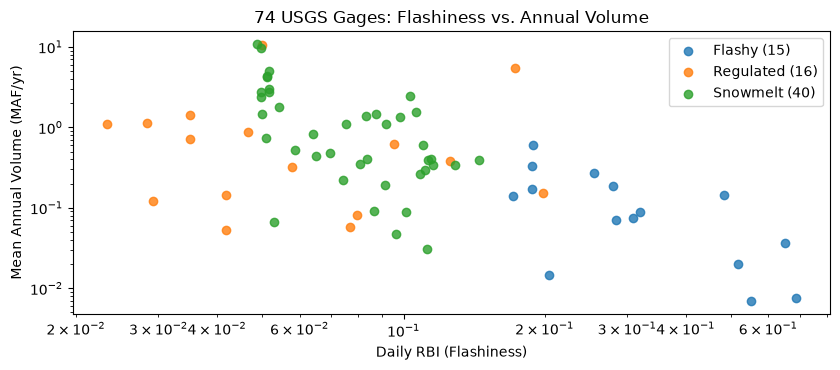

In [4]:
import sqlite3, tempfile, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path

db_path = next((p for p in [Path('data/colorado_river_basin.db'), Path('../data/colorado_river_basin.db'), Path(tempfile.gettempdir()) / 'colorado_river_basin.db'] if p.exists()), None)
conn = sqlite3.connect(db_path)
df_rbi = pd.read_sql_query('''
    SELECT r.station_id, r.station_name, r.flow_regime, r.rbi_index,
           ROUND(AVG(n.mean_cfs) * 0.00072397, 4) AS annual_maf
    FROM rbi_flashiness r JOIN station_daily_normals n ON r.station_id = n.station_id
    GROUP BY r.station_id
''', conn)
print(df_rbi.groupby('flow_regime')[['rbi_index', 'annual_maf']].median().round(3))

fig, ax = plt.subplots(figsize=(8.5, 3.8))
for regime, grp in df_rbi.groupby('flow_regime'):
    ax.scatter(grp['rbi_index'], grp['annual_maf'], label=f'{regime} ({len(grp)})', alpha=0.8)
ax.set(xscale='log', yscale='log', xlabel='Daily RBI (Flashiness)', ylabel='Mean Annual Volume (MAF/yr)', title='74 USGS Gages: Flashiness vs. Annual Volume')
ax.legend(); plt.tight_layout(); plt.show()


## 5. Water-Budget Mass Balance (`2000–2024`) & SQLite → JSON Export
Verifies that 25-year physical supply plus reservoir drawdown equals actual basin depletions (`14.14 MAF/yr`), and demonstrates how SQLite rows are serialized to static JSON for GitHub Pages.


2000–2024 Supply + Drawdown: 14.14 MAF/yr | Depletions + Evap: 14.15 MAF/yr


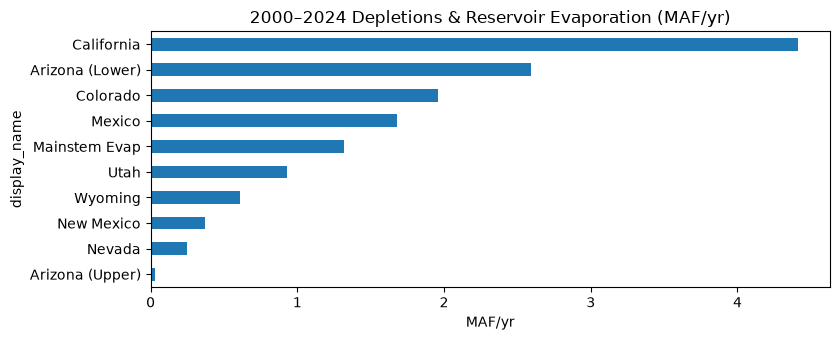

Sample JSON payload: [
  {
    "col_tier": 0,
    "display_name": "Ungaged Side Inflows & Residual",
    "maf_yr": 0.19
  },
  {
    "col_tier": 0,
    "display_name": "Lower Mainstem Gaged Tributaries",
    "maf_yr": 0.36
  },
  {
    "col_tier": 0,
    "display_name": "Net Reservoir Storage Drawdown",
    "maf_yr": 1.19
  },
  {
    "col_tier": 0,
    "display_name": "Upper Basin Natural Flow (Lees Ferry)",
    "maf_yr": 12.4
  }
]


In [5]:
import sqlite3, tempfile, json, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path

db_path = next((p for p in [Path('data/colorado_river_basin.db'), Path('../data/colorado_river_basin.db'), Path(tempfile.gettempdir()) / 'colorado_river_basin.db'] if p.exists()), None)
conn = sqlite3.connect(db_path)
nodes = pd.read_sql_query('SELECT col_tier, display_name, ROUND(maf_yr, 2) AS maf_yr FROM water_budget_nodes WHERE col_tier IN (0, 3) ORDER BY maf_yr', conn)
supply = nodes[nodes['col_tier'] == 0]['maf_yr'].sum()
depletions = nodes[nodes['col_tier'] == 3]['maf_yr'].sum()
print(f'2000–2024 Supply + Drawdown: {supply:.2f} MAF/yr | Depletions + Evap: {depletions:.2f} MAF/yr')

nodes[nodes['col_tier'] == 3].plot.barh(x='display_name', y='maf_yr', figsize=(8.5, 3.5), legend=False, xlabel='MAF/yr', title='2000–2024 Depletions & Reservoir Evaporation (MAF/yr)')
plt.tight_layout(); plt.show()

# Static JSON export pattern used by scripts/export_sqlite_to_json.py:
print('Sample JSON payload:', json.dumps(nodes[nodes['col_tier'] == 0].to_dict(orient='records'), indent=2))
conn.close()
